# 03 — Train three models

Compare the same five training folds. Choose by mean macro F1 and keep the test set for final evaluation.

Open from the notebooks folder. Saved outputs are from the earlier execution; the simplified source has not been rerun in full.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

numeric_columns = [
    'Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
    'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
    'Family_Support', 'Attendance_Rate',
]
categorical_columns = [
    'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
    'Previous_Mental_Health_History',
]

## Load and split the data

In [2]:
df = pd.read_csv('../data/raw/student_mental_health.csv')
X = df[numeric_columns + categorical_columns]
y = df['Mental_Health_Risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Preprocessing and cross-validation

The full pipeline is fitted inside each fold to avoid data leakage.

In [3]:
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Logistic Regression

In [4]:
logistic_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
logistic_scores = cross_validate(logistic_model, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
display(pd.DataFrame(logistic_scores)[['test_accuracy', 'test_f1_macro']])

,test_accuracy,test_f1_macro
0,0.750000,0.745903
1,0.731250,0.733343
2,0.734375,0.730366
3,0.740625,0.738224
4,0.787500,0.788498


## Random Forest

In [5]:
forest_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, random_state=42)),
])
forest_scores = cross_validate(forest_model, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
display(pd.DataFrame(forest_scores)[['test_accuracy', 'test_f1_macro']])

,test_accuracy,test_f1_macro
0,0.703125,0.693049
1,0.662500,0.661265
2,0.675000,0.671854
3,0.687500,0.681308
4,0.637500,0.627315


## Gradient Boosting

In [6]:
boosting_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, early_stopping=False, random_state=42)),
])
boosting_scores = cross_validate(boosting_model, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
display(pd.DataFrame(boosting_scores)[['test_accuracy', 'test_f1_macro']])

,test_accuracy,test_f1_macro
0,0.725000,0.720495
1,0.675000,0.673853
2,0.678125,0.676273
3,0.678125,0.677000
4,0.646875,0.645912


## Compare the scores

In [7]:
comparison = pd.DataFrame({
    'model': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'cv_accuracy': [logistic_scores['test_accuracy'].mean(), forest_scores['test_accuracy'].mean(), boosting_scores['test_accuracy'].mean()],
    'cv_f1': [logistic_scores['test_f1_macro'].mean(), forest_scores['test_f1_macro'].mean(), boosting_scores['test_f1_macro'].mean()],
    'cv_std': [logistic_scores['test_f1_macro'].std(), forest_scores['test_f1_macro'].std(), boosting_scores['test_f1_macro'].std()],
}).sort_values('cv_f1', ascending=False)
display(comparison)

,model,cv_accuracy,cv_f1,cv_std
0,Logistic Regression,0.748750,0.747267,0.021275
2,Gradient Boosting,0.680625,0.678707,0.023892
1,Random Forest,0.673125,0.666958,0.022426


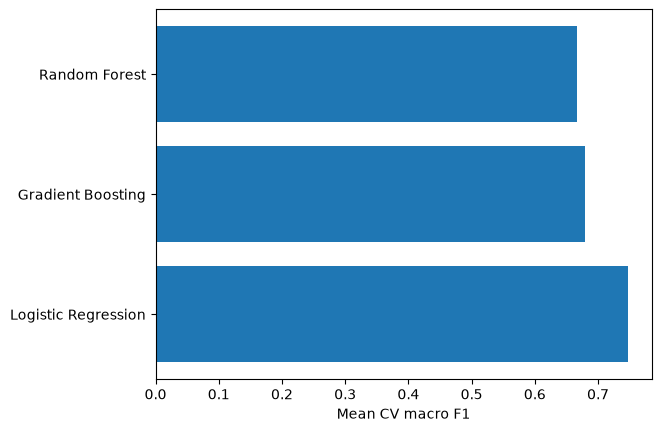

In [8]:
plt.barh(comparison['model'], comparison['cv_f1'])
plt.xlabel('Mean CV macro F1')
plt.show()

## Save the comparison

In [9]:
Path('../models/notebooks').mkdir(exist_ok=True)
comparison.to_csv('../models/notebooks/comparison.csv', index=False)

The recorded comparison places Logistic Regression and Gradient Boosting first. The next notebook tunes them using training data only.